# 15장 · Function Calling의 도구 명세와 호출 요청

도구 명세에는 함수 이름과 받을 인자의 규칙을 적습니다. 모델이 도구 호출을 요청하면 프로그램은 응답에서 함수 이름과 인자를 읽을 수 있습니다.

‘주말에 도서관이 몇 시까지 열어요?’라는 질문에 모델이 함수를 불러 달라고 답했습니다. 아직 운영 시간을 알아낸 것은 아닙니다. 모델이 볼 수 있는 설명과 실제로 프로그램이 돌려줄 값을 구별해 봅시다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## JSON Schema의 enum과 required

도구 명세에는 함수 이름, 기능 설명, 허용 인자를 적습니다. 수업용 가상 도서관은 day 하나만 받고, 평일이나 주말 중 하나를 고르게 했습니다.


### 출력 형식과 호출할 함수

<p>12장의 출력 스키마가 응답 데이터의 모양을 정했다면, 여기서는 get_library_hours가 받을 인자의 모양을 기술합니다. parameters에서 day가 필수인지, 어떤 값을 받을 수 있는지 찾아보세요.</p>


### 셀 01 · parameters의 enum

아래 사전은 함수의 파이썬 본문 없이도 모델에 보낼 수 있는 기능 설명입니다.


In [1]:
import json

TOOL = {
    "type": "function", "name": "get_library_hours",
    "description": "가상 도서관의 요일별 운영 시간을 조회합니다. 실제 예약이나 계정 변경은 하지 않습니다.",
    "parameters": {
        "type": "object",
        "properties": {"day": {"type": "string", "enum": ["weekday", "weekend"]}},
        "required": ["day"], "additionalProperties": False,
    },
    "strict": True,
}

print(TOOL["parameters"]["properties"]["day"]["enum"])

['weekday', 'weekend']


weekday와 weekend가 허용됩니다. 이 명세는 주소나 실제 개관 시간을 제공하지 않습니다. 운영 시간을 조회하는 함수는 다음 장에서 실행합니다.


### 함수 구현과 호출 명세

<p>Python 함수는 프로그램이 실행할 코드입니다. 도구 명세는 모델에게 어떤 기능이 있고 어떤 인자를 받는지 알려 주는 설명입니다. Function Calling에서 모델은 이 명세를 보고 함수 이름과 인자를 포함한 요청을 만들 수 있습니다.</p>

<p>여기서 사용자가 만든 함수는 애플리케이션이 실행해야 합니다. 모델 응답 안에 함수 이름이 나타났다고 내 컴퓨터에서 함수가 실행된 것은 아닙니다. 이번 장은 요청 관찰까지 다루며 실행·결과 반환은 다음 장에서 구현합니다.</p>

<table><caption>서로 다른 세 가지</caption><thead><tr><th scope="col">대상</th><th scope="col">내용</th><th scope="col">이번 장</th></tr>
</thead><tbody><tr><td>구현</td><td>실제로 실행되는 Python 코드</td><td>아직 실행하지 않음</td></tr>
<tr><td>명세</td><td>이름·설명·인자 스키마</td><td>작성</td></tr>
<tr><td>호출 요청</td><td>선택한 함수 이름과 인자</td><td>읽기·관찰</td></tr>
</tbody></table>


### 과제 02 · 필수 필드 목록 required

parameters의 어느 칸에 필수 이름 목록이 있는지 찾아 출력하세요.


In [2]:
# 필수 항목 목록을 꺼내세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(TOOL[&quot;parameters&quot;][&quot;required&quot;])</code></pre>
<p>실행 결과</p><pre><code>[&#x27;day&#x27;]</code></pre>
<p>day가 필수입니다. description은 무엇을 조회할지 설명하지만 입력의 필수 여부는 required에서 읽습니다.</p>
</details>


### 도서관 도구의 인자 스키마

<p>name은 코드에서 찾을 기능의 식별자입니다. description에는 언제 사용하는지와 하지 않는 일을 설명합니다. parameters는 인자의 모양을 정합니다. 이번 day는 weekday와 weekend만 받습니다.</p>

<p>required는 day가 필요함을 뜻하고 additionalProperties=False는 다른 필드 추가를 허용하지 않는 스키마 설정입니다. strict=True를 사용해 지원되는 형식 제약을 요청하지만 실제 실행 전에는 애플리케이션도 입력을 검사해야 합니다.</p>


## function_call의 arguments와 call_id

호출 요청의 arguments는 JSON이 적힌 문자열입니다. 프로그램이 함수에 넘기기 전에 내용을 풀고 명세에 맞는지 검사해야 합니다.

**도구 호출 요청과 실제 실행**　인쇄된 요청서가 나와도 공구함은 닫혀 있습니다. 프로그램이 요청을 읽고 함수를 실행하는 시점을 공구함이 열리는 장면과 연결해 보세요.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter15/index.html#concept-clip)


### 요청의 tools와 응답의 호출 항목

<p>모델에 전달할 tools 목록에는 이 장의 TOOL처럼 이름·설명·인자 규칙을 담습니다. 모델이 도구를 요청하면 응답 항목에서 name, arguments, call_id를 읽습니다. 이 장의 예제는 준비된 응답 항목을 직접 검사합니다.</p>


### 같은 output 목록에서 호출 항목만 모으기

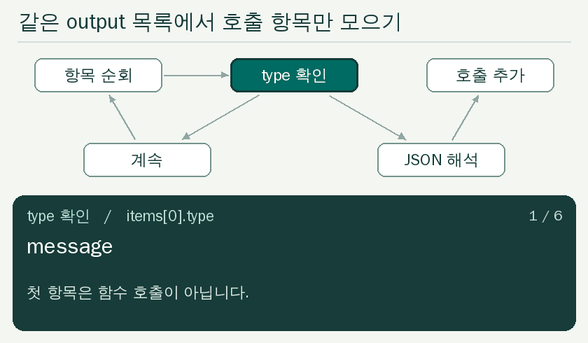

inspect_calls는 먼저 type을 확인합니다. message에서 건너뛴 자리에 가짜 호출을 채우지 않고, function_call에서만 이름과 인자를 읽습니다.


### 셀 03 · arguments의 JSON 디코딩

모델 응답의 모양을 본떠 만든 요청입니다. 호출 ID와 함수명을 그대로 보관합니다.


In [3]:
call = {"type": "function_call", "call_id": "call_demo_1", "name": "get_library_hours",
        "arguments": '{"day":"weekend"}'}
args = json.loads(call["arguments"])
print(args["day"])

weekend


weekend는 확인해 달라고 제안한 인자입니다. 실제 함수가 지금까지 한 번도 실행되지 않았으므로 주말 운영 시간은 아직 모릅니다.


### 호출 ID와 JSON 인자 문자열

<p>call의 arguments는 문자열이라 json.loads를 거쳐야 day를 읽을 수 있습니다. call_id는 그대로 남겨 둡니다. 모델이 같은 이름의 함수를 두 번 요청해도 각각의 결과가 원래 요청으로 돌아가려면 ID가 필요합니다.</p>


### 셀 04 · function_call과 call_id 추출

응답 목록의 첫 항목은 호출 요청이 아닙니다. type을 기준으로 골라야 합니다.

args는 arguments를 풀어서 읽은 값입니다. 다음 단계에서 어느 요청에 답했는지 찾으려면 name·arguments·call_id가 든 호출 원본도 보관해야 합니다. 여기까지는 요청을 읽었을 뿐, 허용된 함수인지와 요일이 올바른지는 실행 전에 검사합니다.


In [4]:
def inspect_calls(items):
    calls = []
    for item in items:
        if item.get("type") != "function_call":
            continue
        args = json.loads(item["arguments"])
        if not isinstance(args, dict):
            raise ValueError("인자는 JSON 객체여야 합니다.")
        calls.append({"call_id": item["call_id"], "name": item["name"], "arguments": args})
    return calls

items = [{"type": "message", "content": []}, call]
print(inspect_calls(items)[0]["call_id"])

call_demo_1


call_demo_1은 골라낸 요청의 식별자입니다. 결과를 돌려줄 때 이 ID가 있어야 어느 요청에 대한 답인지 연결할 수 있습니다.


### 출력 목록에서 호출 선별

<p>모델 응답의 output에는 여러 종류의 항목이 들어갈 수 있습니다. 각 항목의 type을 보고 function_call만 읽습니다. 일반 문장에 “함수를 실행했습니다”라고 쓰여 있어도 호출 요청으로 처리하지 않습니다.</p>

<p>inspect_calls는 인자가 JSON 객체인지까지만 검사합니다. day의 허용값이나 name의 실행 가능 여부는 아직 검사하지 않으며 어떤 함수도 실행하지 않습니다. 이 범위를 다음 장의 실행 검증과 혼동하지 마세요.</p>


## 메시지와 도구 호출 구분

모델은 도구를 항상 요청하는 것이 아닙니다. 사용자에게 전달할 문장만 담긴 응답이라면 실행할 함수도 없습니다.


### 모호한 도구 설명의 영향

<p>설명에 “모든 질문을 처리한다”라고 적으면 기능의 경계가 사라집니다. 운영 시간만 조회하는 도구에는 날짜별 예약 가능 여부나 도서 재고를 처리한다고 적지 않습니다. 실제 구현이 할 수 있는 일만 설명하세요.</p>

<p>인자가 필요한 이유도 분명해야 합니다. day가 요일 이름인지 평일/주말 구분인지 설명되지 않으면 사용자 질문과 스키마가 어긋날 수 있습니다. 허용값과 설명을 함께 읽고 지원하지 않는 질문은 추가 확인 대상으로 남깁니다.</p>


### 과제 05 · 도구 호출 없는 message

글로만 답한 items를 만들고 inspect_calls에 전달해 보세요.


In [5]:
# type이 message인 항목 하나만 있는 목록을 검사하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>items = [{&quot;type&quot;: &quot;message&quot;, &quot;content&quot;: [{&quot;type&quot;: &quot;output_text&quot;, &quot;text&quot;: &quot;질문을 알려 주세요.&quot;}]}]
print(inspect_calls(items))</code></pre>
<p>실행 결과</p><pre><code>[]</code></pre>
<p>빈 목록은 호출 항목을 찾지 못했다는 뜻입니다. 정상 문장이 있는지, 거절인지, 응답이 미완료였는지는 별도로 응답 상태와 내용을 읽어야 합니다.</p>
</details>


### 호출 요청의 관찰 기록

<p>다음 장은 요청의 이름과 인자를 검사하고 Python 함수를 실제로 실행한 뒤 같은 call_id로 결과를 돌려줍니다.</p>


## 돌아보기

함수 이름, call_id, arguments의 day를 각각 한 번 짚어 보세요. 명세에 있는 이름을 보냈다는 기록과 실제 도구의 실행 기록을 나눠 두면 다음 장에서 결과가 빠진 곳을 찾을 수 있습니다.
